In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

sns.set_style("whitegrid")
os.makedirs("images", exist_ok=True)

In [2]:
df=pd.read_csv("data/WA_Fn-UseC_-Telco-Customer-Churn.csv")
print(df.shape)
df.info()
df.head()

(7043, 21)
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df["TotalCharges"]=pd.to_numeric(df["TotalCharges"],errors="coerce")
print(df.isnull().sum()[df.isnull().sum() > 0])

df["TotalCharges"]=df["TotalCharges"].fillna(0)

print("Duplicates:",df.duplicated().sum())
df=df.drop_duplicates()

df["SeniorCitizen"]=df["SeniorCitizen"].map({0:"No", 1:"Yes"})

df["ChurnFlag"]=(df["Churn"]=="Yes").astype(int)

df["TenureGroup"]=pd.cut(df["tenure"],bins=[0,12,24,48,72],labels=["0-12","13-24","25-48","49-72"],include_lowest=True)
df.shape

TotalCharges    11
dtype: int64
Duplicates: 0


(7043, 23)

In [ ]:
overall=df["ChurnFlag"].mean()*100
print(f"Overall churn rate:{overall:.1f}%")

def churn_rate(col):
    return (df.groupby(col,observed=True)["ChurnFlag"].mean()*100).round(1).sort_values(ascending=False)

for col in ["Contract","TenureGroup","PaymentMethod","InternetService","TechSupport","SeniorCitizen"]:
    print(f"\nChurn % by {col}")
    print(churn_rate(col))

print("\nAverage monthly charges by churn")
print(df.groupby("Churn")["MonthlyCharges"].mean().round(2))

Overall churn rate: 26.5%

Churn % by Contract
Contract
Month-to-month    42.7
One year          11.3
Two year           2.8
Name: ChurnFlag, dtype: float64

Churn % by TenureGroup
TenureGroup
0-12     47.4
13-24    28.7
25-48    20.4
49-72     9.5
Name: ChurnFlag, dtype: float64

Churn % by PaymentMethod
PaymentMethod
Electronic check             45.3
Mailed check                 19.1
Bank transfer (automatic)    16.7
Credit card (automatic)      15.2
Name: ChurnFlag, dtype: float64

Churn % by InternetService
InternetService
Fiber optic    41.9
DSL            19.0
No              7.4
Name: ChurnFlag, dtype: float64

Churn % by TechSupport
TechSupport
No                     41.6
Yes                    15.2
No internet service     7.4
Name: ChurnFlag, dtype: float64

Churn % by SeniorCitizen
SeniorCitizen
Yes    41.7
No     23.6
Name: ChurnFlag, dtype: float64

Average monthly charges by churn
Churn
No     61.27
Yes    74.44
Name: MonthlyCharges, dtype: float64


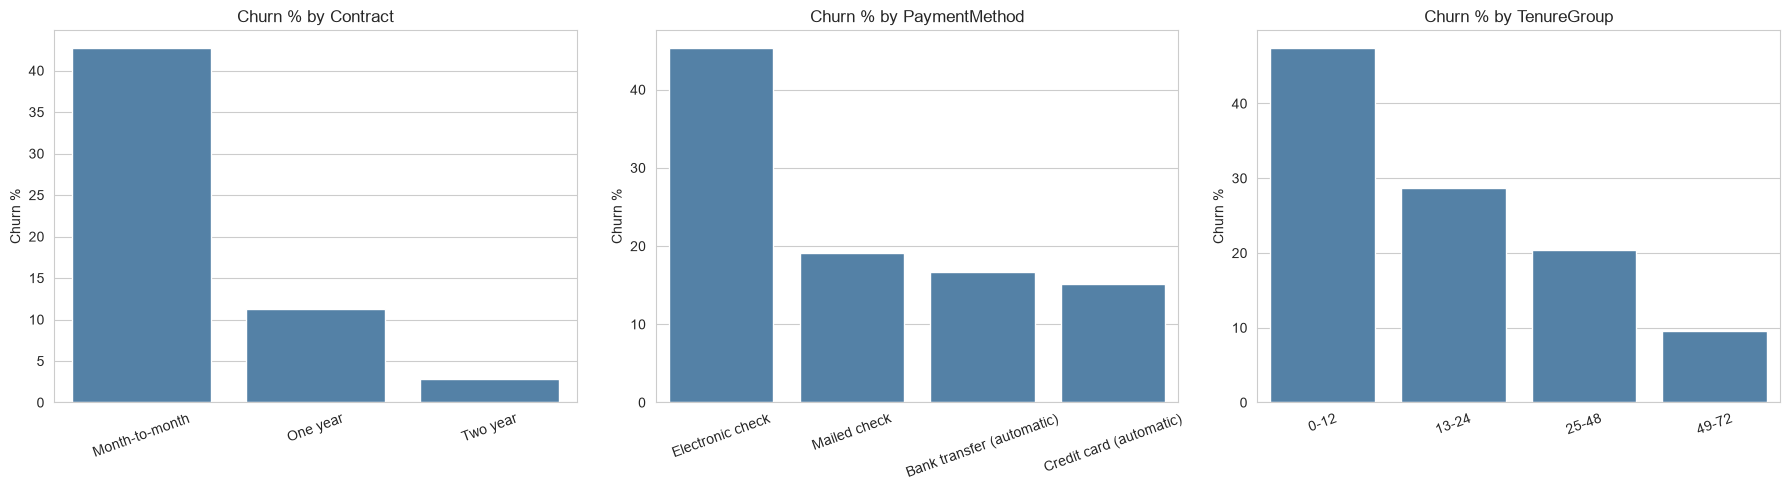

In [5]:
fig,axes=plt.subplots(1,3,figsize=(18,5))
for ax,col in zip(axes,["Contract","PaymentMethod","TenureGroup"]):
    data=churn_rate(col)
    sns.barplot(x=data.index.astype(str),y=data.values,ax=ax,color="steelblue")
    ax.set_title(f"Churn % by {col}")
    ax.set_ylabel("Churn %")
    ax.set_xlabel("")
    ax.tick_params(axis="x",rotation=20)
plt.tight_layout()
plt.savefig("images/churn_bar_charts.png",dpi=150)
plt.show()

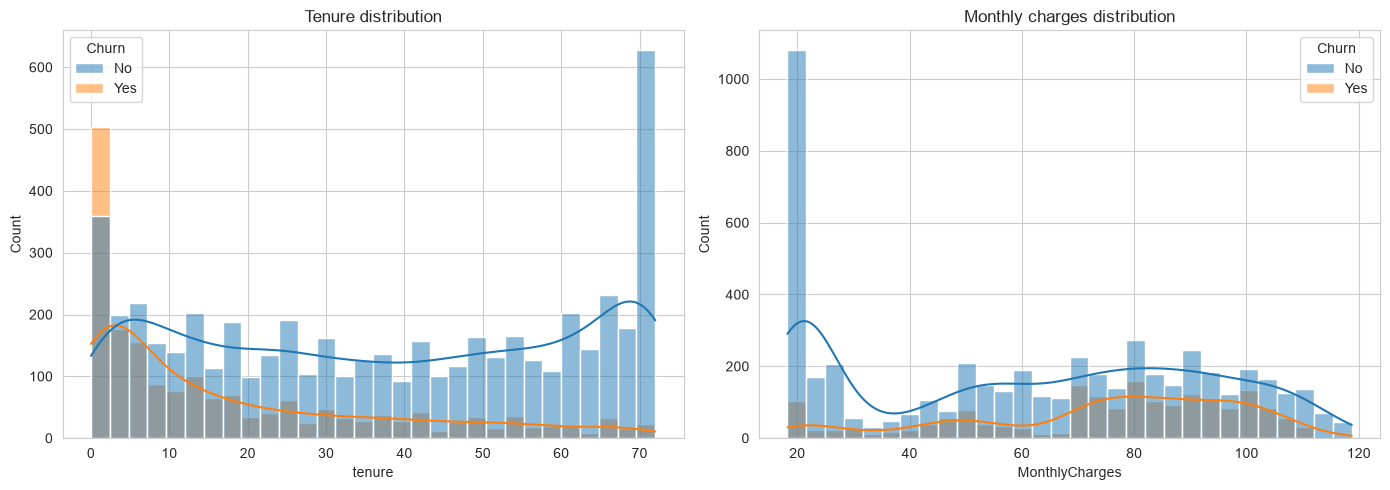

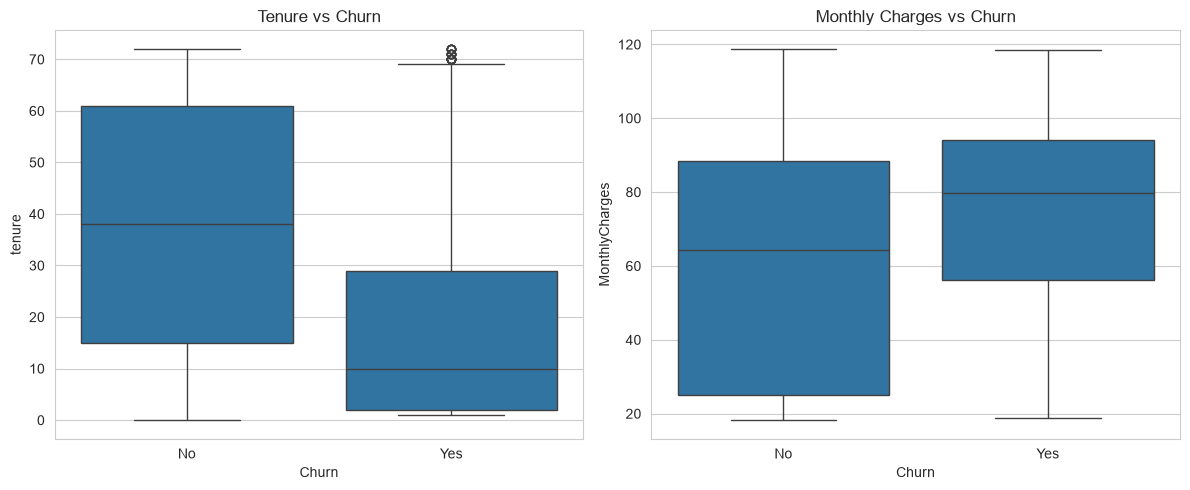

In [6]:
fig,axes=plt.subplots(1,2,figsize=(14,5))
sns.histplot(data=df,x="tenure",hue="Churn",bins=30,kde=True,ax=axes[0])
axes[0].set_title("Tenure distribution")
sns.histplot(data=df,x="MonthlyCharges",hue="Churn",bins=30,kde=True,ax=axes[1])
axes[1].set_title("Monthly charges distribution")
plt.tight_layout()
plt.savefig("images/histograms.png",dpi=150)
plt.show()

fig,axes=plt.subplots(1,2,figsize=(12,5))
sns.boxplot(data=df,x="Churn",y="tenure",ax=axes[0])
axes[0].set_title("Tenure vs Churn")
sns.boxplot(data=df,x="Churn",y="MonthlyCharges",ax=axes[1])
axes[1].set_title("Monthly Charges vs Churn")
plt.tight_layout()
plt.savefig("images/boxplots.png",dpi=150)
plt.show()

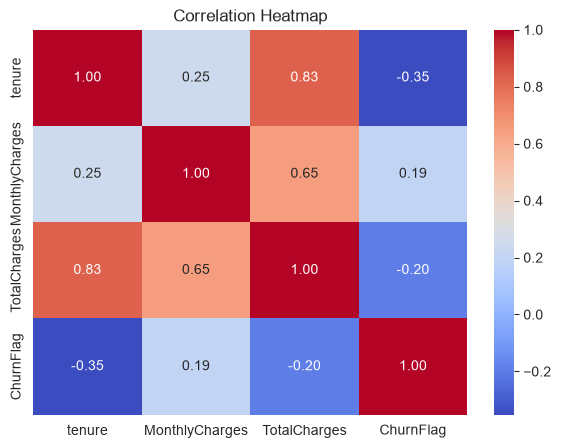

In [7]:
num_cols=["tenure","MonthlyCharges","TotalCharges","ChurnFlag"]
plt.figure(figsize=(7,5))
sns.heatmap(df[num_cols].corr(),annot=True,cmap="coolwarm",fmt=".2f")
plt.title("Correlation Heatmap")
plt.savefig("images/heatmap.png",dpi=150)
plt.show()

## Insights

Overall churn rate is **26.5%**, so roughly 1 in 4 customers leaves.

### Top factors linked to churn
1. **Contract type:** Month-to-month customers churn at 42.7%, versus 11.3% on one-year and only 2.8% on two-year contracts. Contract length is the strongest signal.
2. **Tenure:** Customers in their first 12 months churn at 47.4%, dropping to 9.5% after 49+ months. The median tenure of churned customers is about 10 months, versus about 38 for retained ones. Correlation with churn is -0.35.
3. **Payment method:** Electronic check users churn at 45.3%, nearly 3x the rate of automatic card payers (15.2%) and bank transfer payers (16.7%).
4. **Monthly charges:** Churned customers pay about $74.44 per month on average, versus $61.27 for retained customers (correlation +0.19).

### Recommendations
- Offer discounts or perks to move month-to-month customers onto annual contracts.
- Run an onboarding and check-in program for the first 12 months.
- Encourage auto-pay with a small bill credit, and move people off electronic check.
- Review pricing and value for high-bill customers.

### Limitations
These are correlations, not proof of cause. Electronic check users may also be newer or on month-to-month plans, so factors overlap.